# Supply Chain Order Fulfillment & Delivery Performance Analysis

**Independent portfolio project | Python + pandas + SQL**

## What this project does
Analyzes Olist's public historical marketplace data to measure delivery performance, lead time, seller performance, and the association between late delivery and customer reviews.

## Before running
Download the public dataset from https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce and extract the CSV files. Put them in a folder named `data/` next to this notebook, or upload the CSVs into the current working directory in Colab.

The data is historical Brazilian e-commerce activity (primarily 2016–2018), not current market performance. Do not interpret association as causation.


from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/content")
OUTPUT_DIR = Path("/content/outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("CSV files found:", len(list(DATA_DIR.glob("olist*.csv"))))
print("Available files:")
for f in sorted(DATA_DIR.glob("olist*.csv")):
    print(f.name)


In [10]:
from pathlib import Path

DATA_DIR = Path("/content")
OUTPUT_DIR = Path("/content/outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

files = sorted(DATA_DIR.glob("olist*.csv"))
print("CSV files found:", len(files))

for f in files:
    print(f.name)

CSV files found: 8
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv


In [11]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path("/content")

def read_table(stem, required=True):
    path = DATA_DIR / f"{stem}.csv"
    if not path.exists():
        if required:
            raise FileNotFoundError(f"缺少文件：{path.name}")
        print(f"可选文件不存在：{path.name}")
        return None
    print(f"正在读取：{path.name}")
    return pd.read_csv(path)

orders = read_table("olist_orders_dataset")
items = read_table("olist_order_items_dataset")
sellers = read_table("olist_sellers_dataset")
reviews = read_table("olist_order_reviews_dataset", required=False)
customers = read_table("olist_customers_dataset", required=False)
products = read_table("olist_products_dataset", required=False)

print("\n读取完成！")
print("Orders:", orders.shape)
print("Items:", items.shape)
print("Sellers:", sellers.shape)
print("Reviews:", None if reviews is None else reviews.shape)


正在读取：olist_orders_dataset.csv
正在读取：olist_order_items_dataset.csv
正在读取：olist_sellers_dataset.csv
正在读取：olist_order_reviews_dataset.csv
正在读取：olist_customers_dataset.csv
正在读取：olist_products_dataset.csv

读取完成！
Orders: (99441, 8)
Items: (112650, 7)
Sellers: (3095, 4)
Reviews: (99224, 7)


In [12]:

# 1. 解析订单时间
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# 2. 将商品明细汇总到订单层级，避免重复计算订单
item_summary = items.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "count"),
    item_value=("price", "sum"),
    freight_value=("freight_value", "sum"),
    seller_count=("seller_id", "nunique")
)

# 3. 合并订单和商品数据
df = orders.merge(item_summary, on="order_id", how="left")

# 4. 合并客户评价
review_summary = reviews.groupby("order_id", as_index=False).agg(
    review_score=("review_score", "mean")
)
df = df.merge(review_summary, on="order_id", how="left")

# 5. 计算交付周期和延期天数
df["delivery_days"] = (
    df["order_delivered_customer_date"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df["delay_days"] = (
    df["order_delivered_customer_date"]
    - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# 6. 只统计已送达且实际日期、预计日期完整的订单
delivered = df[
    (df["order_status"] == "delivered")
    & df["order_delivered_customer_date"].notna()
    & df["order_estimated_delivery_date"].notna()
].copy()

delivered["on_time"] = delivered["delay_days"] <= 0

# 7. 输出核心 KPI
print("有效送达订单数：", len(delivered))
print("准时或提前送达率：",
      round(delivered["on_time"].mean() * 100, 2), "%")
print("延期订单率：",
      round((delivered["delay_days"] > 0).mean() * 100, 2), "%")
print("平均交付周期：",
      round(delivered["delivery_days"].mean(), 2), "天")
print("平均延期天数：",
      round(delivered["delay_days"].mean(), 2), "天")

display(delivered[
    ["order_id", "delivery_days", "delay_days", "on_time", "review_score"]
].head(10))


有效送达订单数： 96470
准时或提前送达率： 91.89 %
延期订单率： 8.11 %
平均交付周期： 12.56 天
平均延期天数： -11.18 天


,order_id,delivery_days,delay_days,on_time,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-7.107488,True,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-5.355729,True,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-17.245498,True,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-12.980069,True,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-9.238171,True,5.0
5,a4591c265e18cb1dcee52889e2d8acc3,16.542245,-5.543113,True,4.0
7,6514b8ad8028c9f2cc2374ded245783f,9.989826,-11.461215,True,5.0
8,76c6e866289321a7c93b82b54852dc33,9.818762,-31.410995,True,1.0
9,e69bfb5eb88e0ed6a785585b27e16dbf,18.221852,-6.281597,True,5.0
10,e6ce16cb79ec1d90b1da9085a6118aeb,12.650937,-8.528808,True,1.0


In [14]:

# 1. 按下单月份统计交付表现
delivered["purchase_month"] = (
    pd.to_datetime(delivered["order_purchase_timestamp"])
    .dt.to_period("M").astype(str)
)

monthly = delivered.groupby("purchase_month").agg(
    order_count=("order_id", "count"),
    on_time_rate=("on_time", "mean"),
    avg_delivery_days=("delivery_days", "mean")
).reset_index()

monthly["on_time_rate_pct"] = monthly["on_time_rate"] * 100

display(monthly.sort_values("on_time_rate_pct").head(10))

# 绘制月度准时交付率
plt.figure(figsize=(12, 5))
plt.plot(
    monthly["purchase_month"],
    monthly["on_time_rate_pct"],
    marker="o"
)
plt.title("Monthly On-time or Early Delivery Rate")
plt.xlabel("Purchase Month")
plt.ylabel("On-time or Early Delivery Rate (%)")
plt.xticks(rotation=60, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/outputs/monthly_on_time_rate.png", dpi=160)
plt.show()

# 2. 对比延期订单与准时/提前订单的客户评价
review_comparison = delivered.groupby("on_time").agg(
    order_count=("order_id", "count"),
    avg_review_score=("review_score", "mean")
).reset_index()

review_comparison["delivery_group"] = review_comparison["on_time"].map({
    True: "On-time or early",
    False: "Late"
})

display(review_comparison[
    ["delivery_group", "order_count", "avg_review_score"]
].round(2))

# 3. 单独计算真正延期订单的平均延期天数
late_orders = delivered[delivered["delay_days"] > 0]

print("延期订单数：", len(late_orders))
print(
    "延期订单平均延误天数：",
    round(late_orders["delay_days"].mean(), 2)
)
print(
    "延期订单延误天数中位数：",
    round(late_orders["delay_days"].median(), 2)
)


,purchase_month,order_count,on_time_rate,avg_delivery_days,on_time_rate_pct
0,2016-09,1,0.000000,54.813194,0.000000
17,2018-03,7003,0.786377,16.301410,78.637727
16,2018-02,6555,0.840122,16.945138,84.012204
13,2017-11,7288,0.856888,15.161132,85.688804
22,2018-08,6351,0.896079,7.732780,89.607936
14,2017-12,5513,0.916198,15.394919,91.619808
19,2018-05,6749,0.917617,11.419029,91.761742
6,2017-04,2303,0.921407,14.917913,92.140686
15,2018-01,7069,0.934361,14.080563,93.436130
5,2017-03,2546,0.944226,12.951184,94.422624


NameError: name 'plt' is not defined

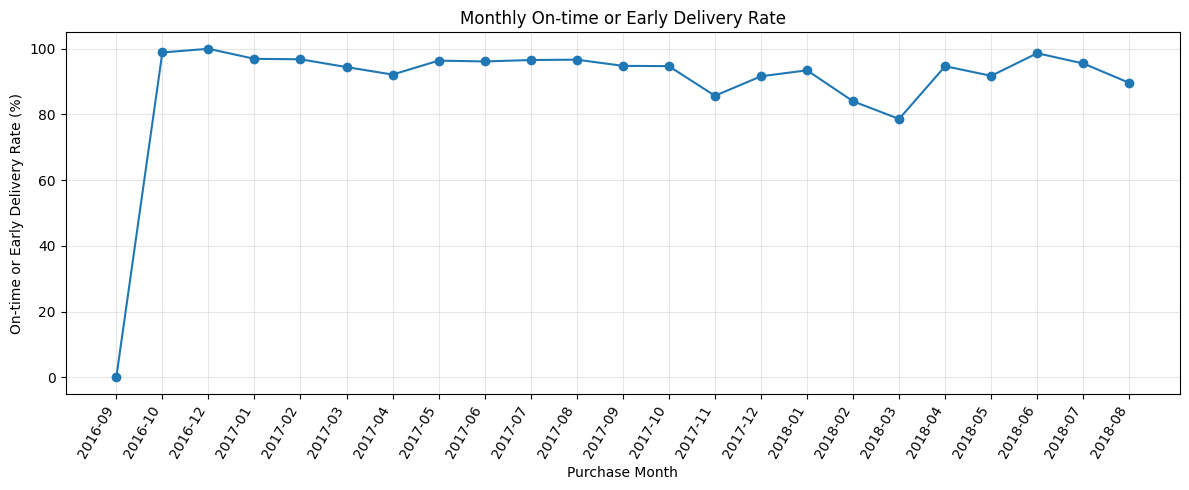

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(
    monthly["purchase_month"],
    monthly["on_time_rate_pct"],
    marker="o"
)
plt.title("Monthly On-time or Early Delivery Rate")
plt.xlabel("Purchase Month")
plt.ylabel("On-time or Early Delivery Rate (%)")
plt.xticks(rotation=60, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/outputs/monthly_on_time_rate.png", dpi=160)
plt.show()


In [16]:

review_comparison = delivered.groupby("on_time").agg(
    order_count=("order_id", "count"),
    avg_review_score=("review_score", "mean")
).reset_index()

review_comparison["delivery_group"] = review_comparison["on_time"].map({
    True: "On-time or early",
    False: "Late"
})

display(
    review_comparison[
        ["delivery_group", "order_count", "avg_review_score"]
    ].round(2)
)

late_orders = delivered[delivered["delay_days"] > 0]

print("延期订单数：", len(late_orders))
print("延期订单平均延误天数：",
      round(late_orders["delay_days"].mean(), 2))
print("延期订单延误天数中位数：",
      round(late_orders["delay_days"].median(), 2))


,delivery_group,order_count,avg_review_score
0,Late,7826,2.57
1,On-time or early,88644,4.29


延期订单数： 7826
延期订单平均延误天数： 9.55
延期订单延误天数中位数： 5.81


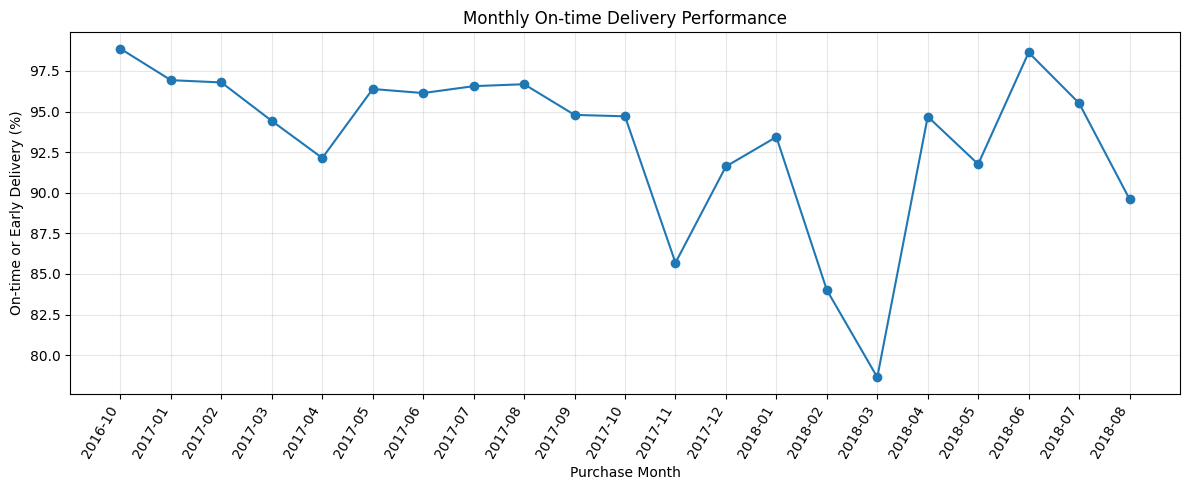

已保存以下项目成果：
core_kpi_summary.csv
monthly_delivery_performance.csv
monthly_delivery_performance.png
monthly_on_time_rate.png
review_comparison.csv


In [17]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

out = Path("/content/outputs")
out.mkdir(exist_ok=True)

# 1. 排除样本量不足的月份
monthly_filtered = monthly[
    monthly["order_count"] >= 100
].copy()

monthly_filtered.to_csv(
    out / "monthly_delivery_performance.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. 重新绘制正式版趋势图
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_filtered["purchase_month"],
    monthly_filtered["on_time_rate_pct"],
    marker="o"
)
plt.title("Monthly On-time Delivery Performance")
plt.xlabel("Purchase Month")
plt.ylabel("On-time or Early Delivery (%)")
plt.xticks(rotation=60, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(out / "monthly_delivery_performance.png", dpi=200)
plt.show()

# 3. 保存评价对比结果
review_comparison.to_csv(
    out / "review_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# 4. 保存核心指标
kpi_summary = pd.DataFrame({
    "metric": [
        "Eligible delivered orders",
        "On-time or early delivery rate (%)",
        "Late delivery rate (%)",
        "Average delivery days",
        "Late order count",
        "Average delay days among late orders",
        "Median delay days among late orders",
        "Average review score: on-time or early",
        "Average review score: late"
    ],
    "value": [
        len(delivered),
        delivered["on_time"].mean() * 100,
        (delivered["delay_days"] > 0).mean() * 100,
        delivered["delivery_days"].mean(),
        len(late_orders),
        late_orders["delay_days"].mean(),
        late_orders["delay_days"].median(),
        delivered.loc[delivered["on_time"], "review_score"].mean(),
        delivered.loc[~delivered["on_time"], "review_score"].mean()
    ]
})

kpi_summary.to_csv(
    out / "core_kpi_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("已保存以下项目成果：")
for f in sorted(out.iterdir()):
    if f.is_file():
        print(f.name)


In [18]:

from pathlib import Path

report = """
# Supply Chain Order Fulfillment Analysis

## 1. Project Objective
Analyze historical order fulfillment performance using public
e-commerce transaction data.

## 2. Key Findings

- 96,470 delivered orders had valid actual and estimated delivery dates.
- The on-time or early delivery rate was 91.89%.
- The late delivery rate was 8.11%.
- Late orders had an average delay of 9.55 days and a median delay
  of 5.81 days.
- Average review score was 2.57 for late orders versus 4.29 for
  on-time or early orders.
- Monthly delivery performance varied, with a notable decline
  in March 2018.

## 3. Operational Recommendations

1. Create an exception-monitoring list for orders approaching their
   estimated delivery date.
2. Track orders with missing carrier handoff timestamps and
   unusually long delivery lead times.
3. Review low-performing months and segments before deciding on
   corrective actions.
4. Compare delivery KPIs alongside order counts and data completeness.
5. Investigate the association between late delivery and lower
   customer ratings without assuming causation.

## 4. Limitations

- The dataset represents historical Brazilian e-commerce activity,
  primarily from 2016 to 2018.
- The findings are descriptive and do not establish causation.
- The analysis is an independent portfolio project, not a project
  conducted for an employer.
- Monthly changes require further investigation before attributing
  them to specific operational causes.
"""

out = Path("/content/outputs")
out.mkdir(exist_ok=True)

(out / "business_findings.md").write_text(
    report.strip(), encoding="utf-8"
)

print("业务发现报告已保存：", out / "business_findings.md")


业务发现报告已保存： /content/outputs/business_findings.md


In [19]:

import shutil

shutil.make_archive(
    "/content/supply_chain_analysis_outputs",
    "zip",
    "/content/outputs"
)

print("打包成功！")


打包成功！


In [ ]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for c in date_cols:
    if c in orders.columns:
        orders[c] = pd.to_datetime(orders[c], errors="coerce")

audit = pd.DataFrame({
    "rows": [len(orders), len(items), len(sellers)],
    "duplicate_rows": [orders.duplicated("order_id").sum(),
                       items.duplicated(["order_id", "order_item_id"]).sum(),
                       sellers.duplicated("seller_id").sum()]
}, index=["orders", "order_items", "sellers"])
display(audit)
display(orders[date_cols].isna().sum().to_frame("missing_timestamps"))
display(orders["order_status"].value_counts(dropna=False).to_frame("orders"))

## 4. Build order-level and seller-level data

In [ ]:
# Aggregate item lines to order level before joining. This avoids multiplying orders
# when an order contains multiple products.
item_agg = items.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "count"),
    item_value=("price", "sum"),
    freight_value=("freight_value", "sum"),
    seller_count=("seller_id", "nunique")
)
primary_seller = (items.sort_values(["order_id", "order_item_id"])
                  .drop_duplicates("order_id")[["order_id", "seller_id"]]
                  .rename(columns={"seller_id": "representative_seller_id"}))

df = orders.merge(item_agg, on="order_id", how="left").merge(primary_seller, on="order_id", how="left")

if customers is not None and "customer_id" in df.columns:
    cust_cols = [c for c in ["customer_id", "customer_state", "customer_city"] if c in customers.columns]
    if len(cust_cols) > 1:
        df = df.merge(customers[cust_cols].drop_duplicates("customer_id"), on="customer_id", how="left")

if reviews is not None:
    review_agg = reviews.groupby("order_id", as_index=False).agg(
        review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
    df = df.merge(review_agg, on="order_id", how="left")

df["delivery_variance_days"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400
df["purchase_to_carrier_days"] = (
    df["order_delivered_carrier_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400
df["purchase_to_delivery_days"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype("string")
df["is_late"] = df["delivery_variance_days"] > 0
df["is_on_time_or_early"] = df["delivery_variance_days"] <= 0

print("Order-level dataset:", df.shape)
display(df.head())

## 5. Define the delivery KPI population

In [ ]:
delivered = df.loc[
    df["order_status"].eq("delivered") &
    df["order_delivered_customer_date"].notna() &
    df["order_estimated_delivery_date"].notna()
].copy()

if delivered.empty:
    raise ValueError("No delivered orders with actual and estimated delivery dates were found.")

kpis = pd.DataFrame({
    "metric": [
        "Delivered orders with both delivery dates",
        "On-time or early delivery rate (%)",
        "Late delivery rate (%)",
        "Average delivery variance (days; positive = late)",
        "Median purchase-to-delivery lead time (days)",
        "Median purchase-to-carrier lead time (days)"
    ],
    "value": [
        len(delivered),
        100 * delivered["is_on_time_or_early"].mean(),
        100 * delivered["is_late"].mean(),
        delivered["delivery_variance_days"].mean(),
        delivered["purchase_to_delivery_days"].median(),
        delivered["purchase_to_carrier_days"].median()
    ]
})
display(kpis.round(2))
kpis.to_csv(OUTPUT_DIR / "delivery_kpis.csv", index=False)

## 6. Monthly delivery performance

In [ ]:
monthly = delivered.groupby("purchase_month", dropna=True).agg(
    delivered_orders=("order_id", "nunique"),
    on_time_rate=("is_on_time_or_early", "mean"),
    avg_variance_days=("delivery_variance_days", "mean"),
    median_lead_time_days=("purchase_to_delivery_days", "median")
).reset_index()
monthly["on_time_rate_pct"] = monthly["on_time_rate"] * 100
monthly.to_csv(OUTPUT_DIR / "monthly_delivery_performance.csv", index=False)
display(monthly.head())

plt.figure(figsize=(12, 5))
plt.plot(monthly["purchase_month"].astype(str), monthly["on_time_rate_pct"], marker="o")
plt.title("On-time or Early Delivery Rate by Purchase Month")
plt.xlabel("Purchase month"); plt.ylabel("On-time or early (%)")
plt.xticks(rotation=60, ha="right"); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "monthly_on_time_rate.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Delivery lead time distribution

In [ ]:
lead = delivered["purchase_to_delivery_days"].dropna()
lead = lead[(lead >= 0) & (lead <= lead.quantile(.99))]
plt.figure(figsize=(9, 5))
plt.hist(lead, bins=35)
plt.title("Purchase-to-Delivery Lead Time (up to 99th percentile)")
plt.xlabel("Days"); plt.ylabel("Orders")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "delivery_lead_time_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
print("Median lead time (days):", round(delivered["purchase_to_delivery_days"].median(), 2))
print("90th percentile lead time (days):", round(delivered["purchase_to_delivery_days"].quantile(.90), 2))

## 8. State-level performance

In [ ]:
if "customer_state" in delivered.columns:
    state_perf = delivered.groupby("customer_state", dropna=False).agg(
        delivered_orders=("order_id", "nunique"),
        on_time_rate=("is_on_time_or_early", "mean"),
        avg_variance_days=("delivery_variance_days", "mean"),
        median_lead_time_days=("purchase_to_delivery_days", "median")
    ).reset_index()
    state_perf["on_time_rate_pct"] = 100 * state_perf["on_time_rate"]
    state_perf = state_perf[state_perf["delivered_orders"] >= 100].sort_values("on_time_rate_pct")
    state_perf.to_csv(OUTPUT_DIR / "state_delivery_performance.csv", index=False)
    display(state_perf.head(15).round(2))
    plot_df = state_perf.head(12).sort_values("on_time_rate_pct")
    plt.figure(figsize=(9, 6))
    plt.barh(plot_df["customer_state"].astype(str), plot_df["on_time_rate_pct"])
    plt.title("Lowest On-time Delivery Rates by State (min. 100 delivered orders)")
    plt.xlabel("On-time or early (%)")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "state_on_time_rate.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Customer state data is not available; skip state comparison.")

## 9. Seller performance

In [ ]:
# Seller analysis is based on a representative seller per order to avoid multiplying
# an order across sellers. Multi-seller orders exist; treat this as a directional proxy.
seller_perf = delivered.dropna(subset=["representative_seller_id"]).groupby(
    "representative_seller_id", as_index=False
).agg(
    delivered_orders=("order_id", "nunique"),
    on_time_rate=("is_on_time_or_early", "mean"),
    avg_variance_days=("delivery_variance_days", "mean"),
    median_lead_time_days=("purchase_to_delivery_days", "median")
)
seller_perf["on_time_rate_pct"] = 100 * seller_perf["on_time_rate"]
MIN_SELLER_ORDERS = 30
eligible_sellers = seller_perf[seller_perf["delivered_orders"] >= MIN_SELLER_ORDERS].copy()
eligible_sellers = eligible_sellers.sort_values("on_time_rate_pct")
eligible_sellers.to_csv(OUTPUT_DIR / "seller_delivery_performance.csv", index=False)
print(f"Sellers with at least {MIN_SELLER_ORDERS} delivered orders:", len(eligible_sellers))
display(eligible_sellers.head(15).round(2))
print("Caution: seller comparisons are descriptive and may be affected by geography, product mix, and sample size.")

## 10. Late delivery and customer reviews

In [ ]:
if "review_score" in delivered.columns:
    review_comparison = delivered.dropna(subset=["review_score", "delivery_variance_days"]).groupby(
        delivered["is_late"].map({True: "Late", False: "On-time or early"})
    ).agg(
        orders=("order_id", "nunique"),
        avg_review_score=("review_score", "mean"),
        median_review_score=("review_score", "median")
    ).reset_index(names="delivery_group")
    display(review_comparison.round(2))
    review_comparison.to_csv(OUTPUT_DIR / "review_by_delivery_status.csv", index=False)
    plt.figure(figsize=(7, 5))
    plt.bar(review_comparison["delivery_group"], review_comparison["avg_review_score"])
    plt.title("Average Review Score by Delivery Timing")
    plt.xlabel("Delivery group"); plt.ylabel("Average review score (1–5)")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "review_by_delivery_status.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Review table unavailable; skip review comparison.")

## 11. Export SQL-ready table

In [ ]:
# Export the order-level analytical table. Also create a SQLite database for SQL practice.
sql_columns = [
    "order_id", "order_status", "purchase_month", "customer_state",
    "representative_seller_id", "item_count", "item_value", "freight_value",
    "delivery_variance_days", "purchase_to_carrier_days",
    "purchase_to_delivery_days", "review_score"
]
sql_columns = [c for c in sql_columns if c in df.columns]
sql_df = df[sql_columns].copy()
sql_df.to_csv(OUTPUT_DIR / "order_fulfillment.csv", index=False)

db_path = OUTPUT_DIR / "order_fulfillment.sqlite"
with sqlite3.connect(db_path) as conn:
    sql_df.to_sql("order_fulfillment", conn, if_exists="replace", index=False)
print("Created:", OUTPUT_DIR / "order_fulfillment.csv")
print("Created:", db_path)

## 12. Findings and business recommendations

Use actual outputs to complete the following. Do not invent values.

### Finding 1 — Delivery performance
- On-time/early delivery rate: **[value from delivery_kpis.csv]**
- Number of delivered orders with valid dates: **[sample size]**
- Operational implication: **[what the observed result suggests]**

### Finding 2 — Where lead time or delay varies
- Period/state/seller with a notable pattern: **[measured result]**
- Possible explanation to investigate: **[hypothesis, not fact]**
- Follow-up action: **[a concrete monitoring or process action]**

### Finding 3 — Customer experience
- Average review score for late orders: **[value]**
- Average review score for on-time/early orders: **[value]**
- Interpretation: **association only; do not claim causation**

### Recommendations
1. Build an exception list for orders approaching the estimated delivery date.
2. Track missing carrier handoff timestamps and unusually long purchase-to-carrier lead times.
3. Compare seller performance only above a minimum sample size and investigate the context before escalating.
4. Report on-time rate together with order count, lead-time distribution, and data completeness.

In [ ]:
summary = [
    "# Generated Run Summary", "",
    f"- Total orders in joined table: {len(df):,}",
    f"- Delivered orders with both delivery dates: {len(delivered):,}",
    f"- On-time or early delivery rate: {100 * delivered['is_on_time_or_early'].mean():.2f}%",
    f"- Late delivery rate: {100 * delivered['is_late'].mean():.2f}%",
    f"- Median purchase-to-delivery lead time: {delivered['purchase_to_delivery_days'].median():.2f} days",
    "",
    "Historical Olist dataset; descriptive results only. See README for limitations."
]
(OUTPUT_DIR / "run_summary.md").write_text("\n".join(summary), encoding="utf-8")
print((OUTPUT_DIR / "run_summary.md").read_text())
print("Review all output tables, sample sizes, and limitations before adding numerical claims to a resume.")